# Particle binning, streamed from the host

> Particles arrive batch by batch from host code. One graph, replayed once per batch, loads the next batch and copies it
> to the GPU while the current batch is binned. The histogram builds up across replays.

**Time:** ~6 min · **Runs on:** CPU (a GPU is picked up automatically and streams larger batches) · **You need:** eagle, hawk, NumPy and matplotlib; read first: {doc}`../graph_across_devices`

Binning is a keyed sum: each particle adds its weight and a count to the cell it falls in. The kernel is
[hawk's particle binning page](https://amasat01.github.io/hawk/content/vocabulary/08_particle_binning.html). The data
does not fit in one array here, or does not exist yet: a loader produces it in batches on the host, as a file reader or a
simulation would. Positions follow a Beta(2, 5) law on `[0, 1)`, each with a weight between 0.5 and 1.5.

**Colab or Kaggle:** run this first cell (it installs the packages and downloads the helper files this notebook uses). Elsewhere it only checks the imports.

In [1]:
# Colab setup, generated by python -m raptor_docs.nb colab_setup (do not edit).
import os

try:
    import google.colab  # noqa: F401
    HOSTED = True  # a Colab runtime
except ImportError:
    HOSTED = "KAGGLE_KERNEL_RUN_TYPE" in os.environ  # a Kaggle kernel

if HOSTED:
    import importlib.metadata, pathlib, re, shutil, subprocess, sys, urllib.request

    gpu = bool(shutil.which("nvidia-smi")) and subprocess.run(["nvidia-smi", "-L"], capture_output=True).returncode == 0
    extra = ""
    if gpu:
        # the CUDA major the runtime already has: a CuPy that is installed, else torch's, else the driver's
        major = None
        for m in ("13", "12"):
            try:
                importlib.metadata.version(f"cupy-cuda{m}x")
                major = m
                break
            except importlib.metadata.PackageNotFoundError:
                pass
        if major is None:
            try:
                import torch
                major = "13" if str(torch.version.cuda).startswith("13") else None
            except ImportError:
                pass
        if major is None:
            smi = re.search(r"CUDA Version: (\d+)", subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)
            major = "13" if smi and int(smi.group(1)) >= 13 else "12"
        extra = f"[cuda{major}]"
        print(f"GPU found: installing the {extra} extras to match this runtime.")
    pre = ["--pre"] if os.environ.get("RAPTOR_PRE") else []  # optional: test a release candidate
    ref = os.environ.get("RAPTOR_REF", "main")  # optional: fetch the helper files from this git ref
    if pre or "RAPTOR_REF" in os.environ:
        print(f"Pre-release test: installing with --pre, helper files from {ref}.")
    # our packages with --upgrade, so a runtime that kept an older release gets the current one
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--upgrade", *pre, f"raptor-eagle{extra}", f"raptor-hawk{extra}"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "matplotlib"])
    base = os.environ.get("RAPTOR_RAW_BASE", "https://raw.githubusercontent.com")  # optional: a local mirror
    top = os.environ.get("RAPTOR_WORKDIR") or ("/kaggle/working" if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "/content")
    root = pathlib.Path(top) / "eagle"
    for rel in (
        "docs/content/_shared/nb_helpers.py",
        "docs/content/_shared/themed_figure.py",
    ):
        (root / rel).parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(f"{base}/amasat01/eagle/{ref}/{rel}", root / rel)
    (root / "docs/content/userguide/tutorials").mkdir(parents=True, exist_ok=True)
    os.chdir(root / "docs/content/userguide/tutorials")
    if not gpu:
        print("Running on the CPU (no GPU in this runtime). For a GPU: " + ("Settings → Accelerator → GPU T4 x2." if "KAGGLE_KERNEL_RUN_TYPE" in os.environ else "Runtime → Change runtime type → T4 GPU."))

try:
    import eagle, hawk, matplotlib  # noqa: F401
except ImportError as err:
    raise ImportError(
        "eagle, hawk, matplotlib not found. Install with `pip install matplotlib raptor-eagle raptor-hawk`. For a GPU, add [cuda12] (or [cuda13]) to raptor-eagle and raptor-hawk."
    ) from err

In [2]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent.parent / "_shared"))
from nb_helpers import gpu_available, plot_style, to_numpy, xp_for

In [3]:
import numpy as np

DEVICE = "gpu" if gpu_available() else "cpu"
xp = xp_for(DEVICE)
BATCH = 2_000_000 if DEVICE == "gpu" else 20_000      # particles per batch
BATCHES = 20
NB = 16                                                # cells
print("running on", DEVICE, f"with {BATCHES} batches of {BATCH:,} particles")

running on cpu with 20 batches of 20,000 particles


## The kernel

`m.index(x * NB, NB)` turns a position into a cell number. `hawk.scatter(mass)[cell] += w` adds the weight there. A sink
you pass in keeps what it holds, so every replay of the graph adds to the same histogram. A floating-point scatter keeps its
rounding correction in a companion that eagle owns and that lasts across replays, so a cell's error stays within
`eps * sum|w|` (`eps` is the machine epsilon) however many batches are binned.

In [4]:
import eagle
import hawk
import hawk.math as m
from hawk import Mutable, Scalar


@hawk.kernel
def deposit(x: Scalar, w: Scalar, mass: Mutable["bin":NB], count: Mutable["bin":NB]):
    cell = m.index(x * NB, NB)
    hawk.scatter(mass)[cell] += w
    hawk.scatter(count)[cell] += 1.0

## The loader, a host function

`batch(k)` is batch number `k`, drawn from its own seed so any batch can be produced again. The loader fills two host
arrays in place. They are page-locked on a GPU (`eagle.pinned`; your decision, not eagle's), so the copy to the device is
a direct transfer that can overlap with kernels. On the CPU they are ordinary arrays.

In [5]:
def batch(k):
    rng = np.random.default_rng(100 + k)
    return rng.beta(2, 5, size=BATCH), rng.uniform(0.5, 1.5, size=BATCH)


def host_array(shape):
    """Page-locked on a GPU; an ordinary array on the CPU."""
    return eagle.pinned(shape) if DEVICE == "gpu" else np.zeros(shape)


class Loader:
    """Fills the host arrays with the next batch each time the graph calls it."""

    def __init__(self, h_x, h_w):
        self.h_x, self.h_w, self.next = h_x, h_w, 1        # batch 0 is placed by hand

    def __call__(self):
        self.h_x[:], self.h_w[:] = batch(self.next)
        self.next += 1

## The graph: load the next batch while this one is binned

A replay has two branches that run together. One loads batch `k + 1` on the host and copies it to the device buffers
`nx`, `nw`. The other bins batch `k`, which is already in `cx`, `cw`. When both are done, `nx`, `nw` are copied over `cx`,
`cw` for the next replay. The two branches touch different arrays, so eagle lets them overlap; the join is the only
wait. (The last replay loads one batch too many, which is never used.)
`eagle.opaque(fn, reads=..., writes=...)` makes your own Python function a graph node; `reads=` and `writes=` tell eagle
which arrays it touches, so it can order it.

In [6]:
h_x, h_w = host_array(BATCH), host_array(BATCH)
loader = Loader(h_x, h_w)
cx, cw = xp.zeros(BATCH), xp.zeros(BATCH)              # the batch being binned
nx, nw = xp.zeros(BATCH), xp.zeros(BATCH)              # the batch on its way
mass, count = xp.zeros(NB), xp.zeros(NB)


@eagle.Graph.builder
def stream(cx, cw, nx, nw, h_x, h_w, mass, count):
    g = eagle.Graph()
    with g.parallel() as p:
        with p.branch():
            eagle.opaque(loader, writes=(h_x, h_w), name="load")        # your function as a node; writes= names what it fills
            eagle.copy(h_x, into=nx)                                     # host -> device
            eagle.copy(h_w, into=nw)
        with p.branch():
            deposit(x=cx, w=cw, mass=mass, count=count)                  # the GPU bins the batch in hand
    eagle.copy(nx, into=cx)                                              # next becomes current (device -> device)
    eagle.copy(nw, into=cw)
    return g


x0, w0 = batch(0)
cx[:], cw[:] = xp.asarray(x0), xp.asarray(w0)                            # batch 0, placed by hand
g = stream(cx, cw, nx, nw, h_x, h_w, mass, count)
print("backend:", g.backend, "| nodes:", g.node_labels())

backend: cpu | nodes: ['load', 'copy', 'copy', 'deposit', 'copy', 'copy']


## The schedule, drawn from the graph

The order the graph allows, taken from its nodes and edges: one time slot per node, and a node starts when everything it
depends on has finished. It is a picture of the structure, not a measurement. The load and the binning start together;
the copies follow the load; the two copies into `cx`, `cw` wait for both.


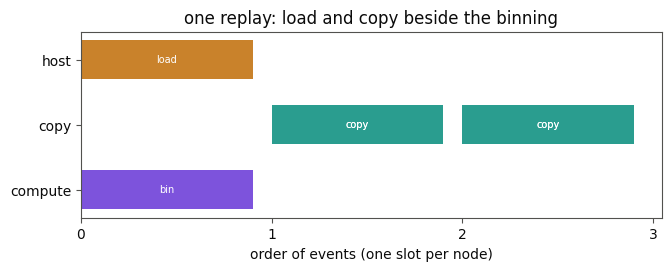
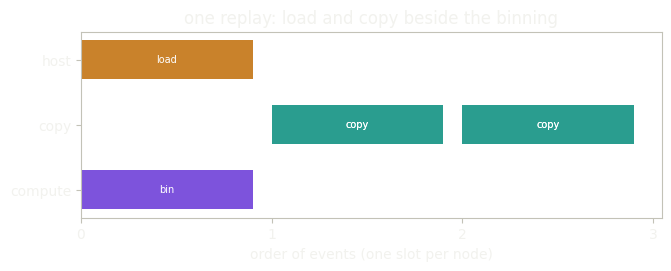

In [7]:
import matplotlib.pyplot as plt
from themed_figure import show

LANES = ("compute", "copy", "host")
COLOURS = {"compute": "#7d53dc", "copy": "#2a9d8f", "host": "#c9822b"}


def lane_of(label):
    if label.startswith("copy"):
        return "copy"
    if label == "load":
        return "host"
    return "compute"


def slots(graph):
    """Each node's start slot: one past the latest node it depends on."""
    after = {}
    for e in graph.edges():
        after.setdefault(e.dst, set()).add(e.src)
    start = {}
    for i in range(graph.num_nodes()):          # edges point forward in add order
        start[i] = 1 + max((start[j] for j in after.get(i, ())), default=-1)
    return start


plot_style()
labels = g.node_labels()
start = slots(g)
fig, ax = plt.subplots(figsize=(6.6, 2.6), constrained_layout=True)
for i, label in enumerate(labels):
    lane = lane_of(label)
    ax.barh(LANES.index(lane), 0.9, left=start[i], color=COLOURS[lane], height=0.6)
    ax.text(start[i] + 0.45, LANES.index(lane), label.replace("deposit", "bin"), ha="center", va="center", fontsize=7, color="white")
ax.set_yticks(range(len(LANES)), LANES)
ax.set_xticks(range(max(start.values()) + 2))
ax.set_xlabel("order of events (one slot per node)")
ax.set_title("one replay: load and copy beside the binning")
show()

## Run it, and check it

`g.launch(BATCHES)` replays the graph once per batch with no host involvement in between other than the loader. Then the
histogram is compared with what NumPy gives for the same batches: the counts must be exactly equal, and the mass of each
cell must be within `eps * sum|w|` of its exactly rounded sum (`math.fsum`) over all the batches. Nothing may be lost: the
counts add up to the number of particles and the cells add up to the total weight.

In [8]:
import math

g.launch(BATCHES)
cells = [np.minimum((batch(k)[0] * NB).astype(int), NB - 1) for k in range(BATCHES)]
weights = [batch(k)[1] for k in range(BATCHES)]
want_count = sum(np.bincount(c, minlength=NB) for c in cells)
got_count, got_mass = to_numpy(count), to_numpy(mass)
assert np.array_equal(got_count, want_count), (got_count, want_count)
assert got_count.sum() == BATCHES * BATCH

# the exactly rounded mass of each cell over ALL batches, and what the contract allows
exact = np.array([math.fsum(np.concatenate([w[c == j] for c, w in zip(cells, weights)])) for j in range(NB)])
bound = np.finfo(float).eps * np.sum([np.bincount(c, np.abs(w), NB) for c, w in zip(cells, weights)], axis=0)
assert np.all(np.abs(got_mass - exact) <= bound)
assert math.isclose(got_mass.sum(), sum(math.fsum(w) for w in weights), rel_tol=1e-12), "no weight is lost"
print(f"{int(got_count.sum()):,} particles binned; counts equal NumPy's exactly; mass conserved")
print(f"worst cell error: {np.max(np.abs(got_mass - exact) / bound):.2f} of the bound eps * sum|w|")

400,000 particles binned; counts equal NumPy's exactly; mass conserved
worst cell error: 0.00 of the bound eps * sum|w|


The result against the law the positions were drawn from. The Beta(2, 5) cumulative form is `1 - (1-x)^5 (1+5x)`; the
outlines show the expected counts.


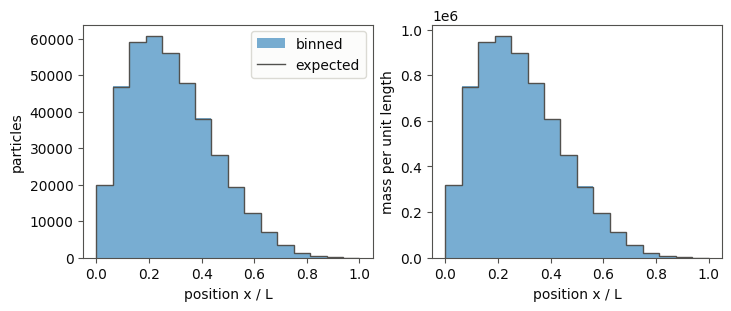
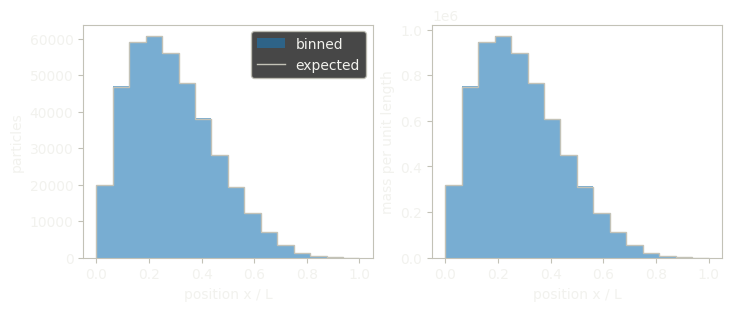

In [9]:
edges = np.arange(NB + 1) / NB
cdf = 1 - (1 - edges) ** 5 * (1 + 5 * edges)
expect = BATCHES * BATCH * np.diff(cdf)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(7.2, 3.0), constrained_layout=True)
a0.stairs(got_count, edges, fill=True, alpha=0.6, label="binned")
a0.stairs(expect, edges, color="#898781", label="expected")
a0.set_xlabel("position x / L"); a0.set_ylabel("particles"); a0.legend()
a1.stairs(got_mass * NB, edges, fill=True, alpha=0.6)
a1.stairs(expect * NB, edges, color="#898781")
a1.set_xlabel("position x / L"); a1.set_ylabel("mass per unit length")
show()

## What just happened

- One graph held a host function, two host-to-device copies, a kernel and two device copies. It was replayed once per
  batch.
- The load and the binning were in different branches, so the loader could work on batch `k + 1` while the GPU binned
  batch `k`. Whether they overlap in time depends on the device; the graph is what makes it allowed.
- The histogram lived in the sinks you passed in, so it accumulated across replays. The totals equal NumPy's over the same
  batches.
- The same builder ran over NumPy arrays on the CPU, with the copies as plain assignments.

## Try this

Raise `BATCHES` to 100: the graph is the same, and the histogram keeps growing.

## Next

- {doc}`22_heat_energy_check`, {doc}`23_fluids_pinned_frames`, {doc}`24_fem_solve_early_stop`: more graphs across the
  host and the device.
- {doc}`../graph_across_devices`: the rules for host nodes and copies.